In [2]:
import numpy as np
import anndata as ad
import pandas as pd
from umap import UMAP


In [3]:
fname = '/work/magroup/skrieger/Syndri/data/label_transfer/SC_NSCLC_labeltransfer_admixed_10reps.h5ad'

adata = ad.read_h5ad(fname)

/tmp/ipykernel_3677896/703491841.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(),rotation=45,ha='right',)


Text(0.5, 1.0, 'Cell Type Count Distribution:\nAll vs. Highly Expressive (>400 total transcripts)')

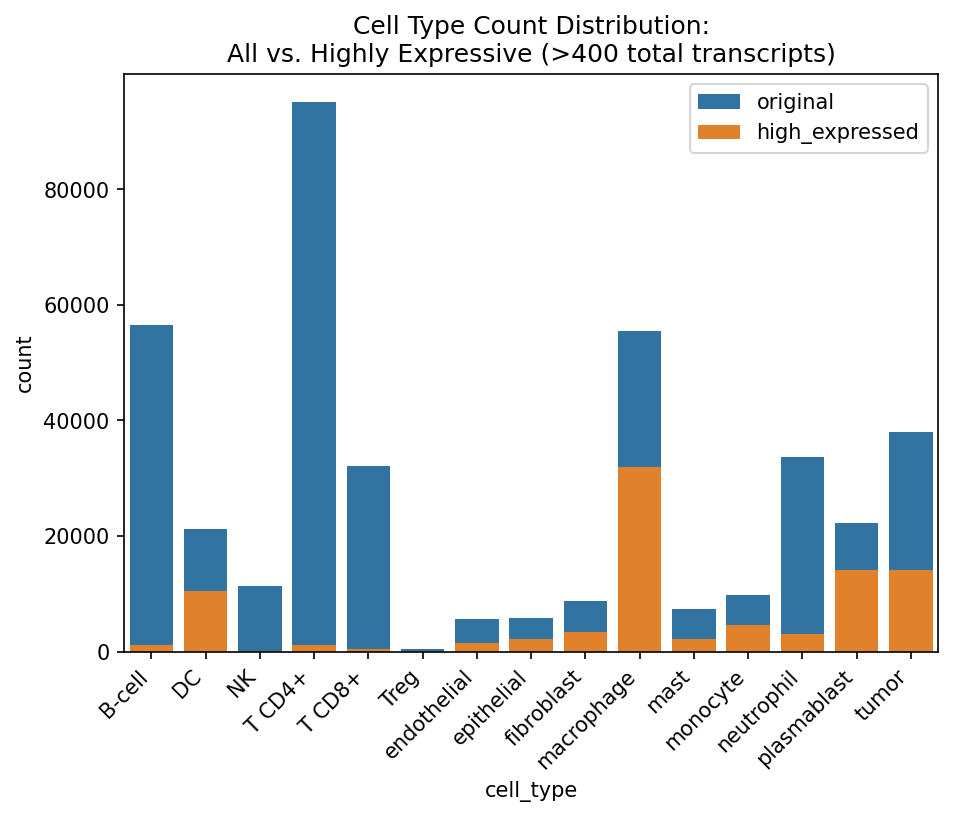

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
fig,ax = plt.subplots(figsize=(7,5),dpi=150)

sns.countplot(data=adata.obs,x='cell_type',label='original',ax=ax)
sns.countplot(data=adata[adata.X.sum(1)>400].obs,x='cell_type',label='high_expressed',ax=ax)
ax.set_xticklabels(ax.get_xticklabels(),rotation=45,ha='right',)
ax.set_title('Cell Type Count Distribution:\nAll vs. Highly Expressive (>400 total transcripts)')

In [5]:
adata[adata.X.sum(1)>400].obs['cell_type'].value_counts()

cell_type
macrophage     31990
tumor          14200
plasmablast    14140
DC             10540
monocyte        4580
fibroblast      3430
neutrophil      3070
mast            2160
epithelial      2120
endothelial     1430
B-cell          1180
T CD4+          1180
T CD8+           470
NK               140
Treg              30
Name: count, dtype: int64

In [6]:
zero_mask = np.array((adata.X.sum(axis=0) == 0)).ravel()
genes_to_drop = adata.var_names[zero_mask]
gene_to_remove = genes_to_drop[0]
zero_gene_mask = ~(adata.var_names == gene_to_remove)
zero_gene_mask

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,

In [7]:
adata = adata[:,zero_gene_mask]

In [8]:
cell_types = sorted(adata.obs['cell_type'].unique())
cell_type_dict = {cell_types[i]: -(i+1) for i in range(len(cell_types))}
cell_type_dict



{'B-cell': -1,
 'DC': -2,
 'NK': -3,
 'T CD4+': -4,
 'T CD8+': -5,
 'Treg': -6,
 'endothelial': -7,
 'epithelial': -8,
 'fibroblast': -9,
 'macrophage': -10,
 'mast': -11,
 'monocyte': -12,
 'neutrophil': -13,
 'plasmablast': -14,
 'tumor': -15}

In [9]:
adata.uns['cell_type_dict'] = cell_type_dict
adata.write_h5ad('/work/magroup/skrieger/Syndri/data/label_transfer/SC_NSCLC_labeltransfer_admixed_10reps.h5ad')

/tmp/ipykernel_3677896/3352316741.py:1: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns['cell_type_dict'] = cell_type_dict
